# 06 — Model development

## Purpose

We evaluate how different calendar and astronomical feature representations affect short-term photovoltaic power forecasting. The study uses SOLETE power and weather observations at 5-minute resolution and forecasts PV power 15, 30, and 60 minutes ahead.

The main question is whether **F4 (F3 plus Vedic Panchang categories)** reduces forecasting error compared with **F3 (continuous solar and lunar astronomy)**. We also compare the earlier feature additions and test a stronger continuous astronomical reference.

We use the same LightGBM configuration for every representation and compare their predictions on the same chronological validation samples.

## 1. Forecasting model and validation design

We use LightGBM, a gradient-boosted tree model. Its configuration was selected during the earlier SOLETE development experiments and is held constant here: **300 trees, learning rate 0.03, and 15 leaves**. The remaining settings follow the established LightGBM model definition in `src/classical_models.py`.

Three expanding chronological folds provide the development comparisons. In each fold, the model is fitted using earlier observations and evaluated on a later period. A 60-minute separation between the training target times and the first validation forecast issue time ensures that training labels are available when forecasts are issued.

The analysis uses mean absolute error (**MAE**, in kW) as its primary measure and root mean squared error (**RMSE**, in kW) as a complementary measure. Smaller values indicate more accurate forecasts.

The fixed model settings provide a controlled comparison of the feature representations. They were established in earlier project research, so the results are interpreted as a **retrospective development analysis**.

In [1]:
from pathlib import Path
import gc
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (
        directory for directory in [Path.cwd(), *Path.cwd().parents]
        if (directory / "solete_dataset" / "SOLETE_Pombo_5min.h5").is_file()
        and (directory / "src" / "forecasting_protocol.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the SOLETE project.")
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_solete
from src.preprocessing import build_cleaned_solete_features, build_gregorian_features
from src.astronomy_features import (
    build_lunar_f3_features,
    build_solar_f2_features,
    load_jpl_ephemeris,
    solete_astronomy_reference_times,
    tropical_longitudes_for_solete,
)
from src.vedic_calendar import (
    build_panchang_f4_raw,
    lahiri_ayanamsha_for_utc_times,
    sidereal_longitude_from_tropical,
    yoga_angle_from_tropical_longitudes,
)
from src.feature_families import (
    FEATURE_FAMILY_COUNTS,
    encode_panchang_fixed_vocabulary,
)
from src.forecasting_protocol import (
    CV_FOLDS,
    FORECAST_HORIZONS,
    MODEL_AVAILABILITY_GAP,
    build_f0_history,
    build_forecast_targets,
    build_base_modelling_tables,
    make_rolling_origin_masks,
    terminal_holdout_mask,
    validate_rolling_origin_counts,
)
from src.classical_models import build_lightgbm_model

MODEL_CONFIG = {"n_estimators": 300, "learning_rate": 0.03, "num_leaves": 15}
HORIZONS = (15, 30, 60)
FEATURE_NAMES = (
    "F0", "F1", "F2", "F3", "F4",
    "F3_sidereal", "F4_sidereal",
)

fold_design = pd.DataFrame([
    {
        "fold": spec["fold"],
        "training_from_UTC": spec["train_start"],
        "validation_from_UTC": spec["validation_start"],
        "validation_until_UTC_exclusive": spec["validation_end"],
    }
    for spec in CV_FOLDS
])
assert MODEL_AVAILABILITY_GAP == pd.Timedelta(minutes=60)
assert HORIZONS == tuple(FORECAST_HORIZONS)
print("Model: LightGBM | 300 trees | learning rate 0.03 | 15 leaves")
print("Training-label availability gap:", MODEL_AVAILABILITY_GAP)
display(fold_design)


Model: LightGBM | 300 trees | learning rate 0.03 | 15 leaves
Training-label availability gap: 0 days 01:00:00


,fold,training_from_UTC,validation_from_UTC,validation_until_UTC_exclusive
0,1,2018-06-01 00:00:00+00:00,2018-12-01 00:00:00+00:00,2019-02-01 00:00:00+00:00
1,2,2018-06-01 00:00:00+00:00,2019-02-01 00:00:00+00:00,2019-04-01 00:00:00+00:00
2,3,2018-06-01 00:00:00+00:00,2019-04-01 00:00:00+00:00,2019-06-01 00:00:00+00:00


## 2. Prepare the forecasting samples

The observational features contain recent PV power, irradiance, weather and the previous-day PV value. These 118 F0 predictors are calculated from observations available at forecast issue time.

For each horizon, the forecast target is the PV power at its forecast-valid time. We use the same samples and target values for every feature representation.

In [2]:
DATA_FILE = PROJECT_ROOT / "solete_dataset" / "SOLETE_Pombo_5min.h5"
EPHEMERIS_FILE = PROJECT_ROOT / "ephemeris" / "de440s.bsp"
if not EPHEMERIS_FILE.is_file():
    raise FileNotFoundError(f"Missing astronomical ephemeris: {EPHEMERIS_FILE}")

observations = load_solete(DATA_FILE).sort_index()
cleaned = build_cleaned_solete_features(observations)
f0_history = build_f0_history(cleaned)
targets = build_forecast_targets(cleaned)
base_tables = build_base_modelling_tables(
    cleaned, f0_history=f0_history, target_tables=targets,
)

population = []
for horizon in HORIZONS:
    base = base_tables[horizon]
    assert validate_rolling_origin_counts(base["valid_time"], horizon)
    assert int(terminal_holdout_mask(base["valid_time"]).sum()) == 26496
    population.append({
        "horizon_min": horizon,
        "eligible_rows": len(base),
        "development_validation_rows": sum(
            int(fold["validation_mask"].sum())
            for fold in make_rolling_origin_masks(base["valid_time"])
        ),
    })

display(pd.DataFrame(population))
assert [row["eligible_rows"] for row in population] == [131325, 131322, 131316]
assert f0_history.shape[1] == 118


,horizon_min,eligible_rows,development_validation_rows
0,15,131325,52404
1,30,131322,52404
2,60,131316,52404


## 3. Calculate the calendar and astronomical features

The deterministic feature blocks follow the same definitions as the previous notebooks:

- **F1:** 15 Gregorian calendar variables.
- **F2:** 5 solar-position variables.
- **F3:** 9 continuous lunar and Sun–Moon variables.
- **F4:** 97 Panchang indicator variables covering Tithi, Paksha, Karana, Nakshatra and Yoga.

We also calculate four continuous sidereal-angle variables derived from the same Sun–Moon state. These allow us to compare categorical Panchang features against a more complete continuous representation.

Calendar and astronomical values are selected at the forecast-valid timestamp. SOLETE astronomical calculations represent each 5-minute interval using its timestamp plus two minutes.

In [3]:
times = cleaned.index
calendar = build_gregorian_features(times)
solar = build_solar_f2_features(times)

# Build lunar information in batches to keep memory use moderate.
ephemeris = load_jpl_ephemeris(EPHEMERIS_FILE)
BATCH_SIZE = 8192
lunar_pieces = []
longitude_pieces = []
for start in range(0, len(times), BATCH_SIZE):
    batch = times[start:start + BATCH_SIZE]
    lunar_pieces.append(build_lunar_f3_features(batch, ephemeris))
    longitude_pieces.append(tropical_longitudes_for_solete(batch, ephemeris))
lunar = pd.concat(lunar_pieces)
longitudes = pd.concat(longitude_pieces)
del lunar_pieces, longitude_pieces, ephemeris
gc.collect()

ayanamsha = pd.Series(
    lahiri_ayanamsha_for_utc_times(solete_astronomy_reference_times(times)),
    index=times,
)
panchang = build_panchang_f4_raw(
    longitudes["sun_tropical_longitude_deg"],
    longitudes["moon_tropical_longitude_deg"],
    ayanamsha,
)
panchang.columns = [f"valid_{col}" for col in panchang.columns]
panchang_indicators = encode_panchang_fixed_vocabulary(panchang)

moon_sidereal = sidereal_longitude_from_tropical(
    longitudes["moon_tropical_longitude_deg"], ayanamsha,
)
yoga_angle = yoga_angle_from_tropical_longitudes(
    longitudes["sun_tropical_longitude_deg"],
    longitudes["moon_tropical_longitude_deg"],
    ayanamsha,
)
sidereal_angles = pd.DataFrame({
    "moon_sidereal_sin": np.sin(np.deg2rad(moon_sidereal)),
    "moon_sidereal_cos": np.cos(np.deg2rad(moon_sidereal)),
    "yoga_angle_sin": np.sin(np.deg2rad(yoga_angle)),
    "yoga_angle_cos": np.cos(np.deg2rad(yoga_angle)),
}, index=times)
del longitudes, moon_sidereal, yoga_angle, ayanamsha, panchang
gc.collect()

feature_blocks = {
    "calendar": calendar,
    "solar": solar,
    "lunar": lunar,
    "panchang": panchang_indicators,
    "sidereal": sidereal_angles,
}
assert [x.shape[1] for x in feature_blocks.values()] == [15, 5, 9, 97, 4]
for name, block in feature_blocks.items():
    assert block.index.equals(times)
    assert block.columns.is_unique
    assert np.isfinite(block.to_numpy(dtype=float)).all(), name
assert (panchang_indicators.sum(axis=1) == 5).all()
print("Feature blocks (variables added):")
display(pd.Series({name: block.shape[1] for name, block in feature_blocks.items()}))


Feature blocks (variables added):


calendar    15
solar        5
lunar        9
panchang    97
sidereal     4
dtype: int64

## 4. Build the matched feature representations

For every forecast horizon, **F0** contains the observed history at issue time. The later feature families add valid-time information:

| Representation | Predictors |
|---|---:|
| F0 | 118 |
| F1 | 133 |
| F2 | 138 |
| F3 | 147 |
| F4 | 244 |
| F3 + continuous sidereal angles | 151 |
| F4 + continuous sidereal angles | 248 |

Comparing F3 with F4 measures the effect of adding Panchang categories to the basic continuous astronomical features. Comparing the last two rows measures that effect after explicitly including the four continuous sidereal-angle variables.

In [4]:
EXPECTED_COLUMNS = {
    "F0": 118, "F1": 133, "F2": 138, "F3": 147,
    "F4": 244, "F3_sidereal": 151, "F4_sidereal": 248,
}
assert FEATURE_FAMILY_COUNTS == {
    key: EXPECTED_COLUMNS[key] for key in ("F0", "F1", "F2", "F3", "F4")
}


def align_valid_features(block, base, prefix="valid_"):
    # Deterministic features describe each target's forecast-valid time.
    aligned = block.loc[pd.DatetimeIndex(base["valid_time"])].copy()
    aligned.index = base.index
    return aligned.add_prefix(prefix)


# Each representation is assembled from the same aligned building blocks.
COMPONENTS = {
    "F0": ("history",),
    "F1": ("history", "calendar"),
    "F2": ("history", "calendar", "solar"),
    "F3": ("history", "calendar", "solar", "lunar"),
    "F4": ("history", "calendar", "solar", "lunar", "panchang"),
    "F3_sidereal": ("history", "calendar", "solar", "lunar", "sidereal"),
    "F4_sidereal": ("history", "calendar", "solar", "lunar", "panchang", "sidereal"),
}


def align_feature_components(horizon):
    base = base_tables[horizon]
    pieces = {
        "history": f0_history.loc[base.index].copy(),
        "calendar": align_valid_features(calendar, base),
        "solar": align_valid_features(solar, base),
        "lunar": align_valid_features(lunar, base),
        "panchang": align_valid_features(panchang_indicators, base, prefix=""),
        "sidereal": align_valid_features(sidereal_angles, base),
    }
    for part in pieces.values():
        assert part.index.equals(base.index)
        assert part.columns.is_unique
    for family, components in COMPONENTS.items():
        names = [name for component in components for name in pieces[component].columns]
        assert len(names) == EXPECTED_COLUMNS[family]
        assert len(names) == len(set(names))
    return pieces


def feature_array(pieces, family):
    # Building one numerical matrix at a time reduces memory use.
    values = np.concatenate(
        [pieces[component].to_numpy(dtype=np.float32) for component in COMPONENTS[family]],
        axis=1,
    )
    assert values.shape[1] == EXPECTED_COLUMNS[family]
    assert np.isfinite(values).all()
    return values

print("Feature representations:")
display(pd.Series(EXPECTED_COLUMNS, name="predictors").to_frame())


Feature representations:


,predictors
F0,118
F1,133
F2,138
F3,147
F4,244
F3_sidereal,151
F4_sidereal,248


## 5. Train and evaluate the models

We fit one LightGBM model for each representation, forecast horizon and development fold, using the fixed model configuration. Each fitted model predicts the same later validation timestamps as the other representations.

We also score two practical baselines on those matched samples:

- **Issue-time persistence:** PV power at forecast issue time.
- **Previous-day persistence:** PV power at the forecast-valid time minus 24 hours.

Both **all-hours** and **daylight-only** scores are calculated from the corresponding validation predictions. The predictions are retained for paired error analysis in the next notebook.

In [5]:
def add_scores(rows, *, horizon, fold, method, actual, estimate, daylight):
    errors = np.asarray(actual, dtype=float) - np.asarray(estimate, dtype=float)
    assert np.isfinite(errors).all()
    for scope, mask in (
        ("all", np.ones(len(errors), dtype=bool)),
        ("daylight", np.asarray(daylight, dtype=bool)),
    ):
        selected = errors[mask]
        assert selected.size > 0
        rows.append({
            "horizon_min": horizon,
            "fold": fold,
            "scope": scope,
            "method": method,
            "n": int(selected.size),
            "mae_kw": float(np.mean(np.abs(selected))),
            "rmse_kw": float(np.sqrt(np.mean(selected**2))),
        })


metric_rows = []
prediction_tables = []
for horizon in HORIZONS:
    base = base_tables[horizon]
    aligned_components = align_feature_components(horizon)
    actual = base["target_P_Solar_kW"].to_numpy(dtype=float)
    issue_power = cleaned.loc[base.index, "P_Solar[kW]"].to_numpy(dtype=float)
    prev_day_times = pd.DatetimeIndex(base["valid_time"]) - pd.Timedelta(hours=24)
    previous_day_power = cleaned.loc[prev_day_times, "P_Solar[kW]"].to_numpy(dtype=float)
    daylight = align_valid_features(solar[["solar_daylight"]], base)[
        "valid_solar_daylight"
    ].to_numpy(dtype=bool)
    folds = make_rolling_origin_masks(base["valid_time"])

    # Prepare one matched prediction table for each development fold.
    by_fold = {}
    fold_masks = {}
    for fold_spec, masks in zip(CV_FOLDS, folds, strict=True):
        fold = fold_spec["fold"]
        train = masks["train_mask"].to_numpy(dtype=bool)
        validation = masks["validation_mask"].to_numpy(dtype=bool)
        assert base["valid_time"].loc[train].max() < base["issue_time"].loc[validation].min()
        assert not (train & validation).any()
        fold_masks[fold] = (train, validation)
        valid_time = base["valid_time"].loc[validation]
        df = pd.DataFrame({
            "horizon_min": horizon,
            "fold": fold,
            "issue_time_UTC": base.index[validation].astype(str),
            "valid_time_UTC": valid_time.astype(str).to_numpy(),
            "actual_kw": actual[validation],
            "daylight": daylight[validation].astype("int8"),
            "issue_persistence": issue_power[validation],
            "previous_day_persistence": previous_day_power[validation],
        })
        by_fold[fold] = df
        for baseline in ("issue_persistence", "previous_day_persistence"):
            add_scores(
                metric_rows, horizon=horizon, fold=fold,
                method=baseline, actual=actual[validation],
                estimate=df[baseline].to_numpy(), daylight=daylight[validation],
            )

    # One feature representation at a time limits memory use.
    for family in FEATURE_NAMES:
        matrix = feature_array(aligned_components, family)
        for fold in (1, 2, 3):
            train, validation = fold_masks[fold]
            estimator = build_lightgbm_model(MODEL_CONFIG)
            estimator.fit(matrix[train], actual[train])
            estimated = estimator.predict(matrix[validation])
            assert len(estimated) == int(validation.sum())
            assert np.isfinite(estimated).all()
            by_fold[fold][family] = estimated
            add_scores(
                metric_rows, horizon=horizon, fold=fold, method=family,
                actual=actual[validation], estimate=estimated,
                daylight=daylight[validation],
            )
            del estimator
        del matrix
        gc.collect()
    prediction_tables.extend(by_fold[fold] for fold in (1, 2, 3))
    print(f"{horizon}-minute horizon: seven representations × three folds scored")
    del aligned_components
    gc.collect()

metrics = pd.DataFrame(metric_rows)
predictions = pd.concat(prediction_tables, ignore_index=True)
assert len(metrics) == 3 * 3 * 2 * 9
assert len(predictions) == sum(row["development_validation_rows"] for row in population)
assert predictions.duplicated(["horizon_min", "issue_time_UTC"]).sum() == 0
assert predictions["actual_kw"].notna().all()
assert predictions[list(FEATURE_NAMES)].notna().all().all()
assert set(metrics["scope"]) == {"all", "daylight"}

print("Forecasts and scores produced:")
display(pd.Series({
    "matched_validation_predictions": len(predictions),
    "metrics_rows": len(metrics),
    "LightGBM_models_fitted": 3 * 3 * len(FEATURE_NAMES),
}, name="count").to_frame())


15-minute horizon: seven representations × three folds scored
30-minute horizon: seven representations × three folds scored
60-minute horizon: seven representations × three folds scored
Forecasts and scores produced:


,count
matched_validation_predictions,157212
metrics_rows,162
LightGBM_models_fitted,63


## 6. Compare forecasting accuracy

The main table shows the average MAE across the three development folds. Each fold contributes equally to the mean. Comparing models on matched fold populations isolates the effect of adding the corresponding feature block under this LightGBM configuration.

For the paired feature comparisons, a **positive MAE reduction** means the augmented representation performed better; a negative value means the reference representation performed better.

In [6]:
fold_means = (
    metrics.groupby(["horizon_min", "scope", "method"], as_index=False)
    .agg(mean_fold_mae_kw=("mae_kw", "mean"), mean_fold_rmse_kw=("rmse_kw", "mean"))
)
all_hours = fold_means.loc[fold_means["scope"].eq("all")]
accuracy_table = all_hours.pivot(
    index="horizon_min", columns="method", values="mean_fold_mae_kw"
)
print("All-hours mean development-fold MAE (kW):")
display(accuracy_table.round(5))

COMPARISONS = (
    ("Gregorian", "F0", "F1"),
    ("Solar", "F1", "F2"),
    ("Continuous lunar", "F2", "F3"),
    ("Panchang", "F3", "F4"),
    ("Panchang with sidereal control", "F3_sidereal", "F4_sidereal"),
)
contrast_rows = []
for (horizon, scope), portion in fold_means.groupby(["horizon_min", "scope"]):
    scores = portion.set_index("method")["mean_fold_mae_kw"]
    for label, reference, augmented in COMPARISONS:
        contrast_rows.append({
            "horizon_min": horizon,
            "scope": scope,
            "comparison": label,
            "reference": reference,
            "augmented": augmented,
            "mae_reduction_kw": float(scores[reference] - scores[augmented]),
            "relative_reduction_pct": float(100 * (1 - scores[augmented] / scores[reference])),
        })
contrasts = pd.DataFrame(contrast_rows)
print("Paired feature additions — all hours (positive means lower MAE with added features):")
display(contrasts.loc[contrasts["scope"].eq("all")].round(5))
print("Panchang comparisons — daylight only:")
display(contrasts.loc[
    contrasts["scope"].eq("daylight") &
    contrasts["comparison"].str.startswith("Panchang")
].round(5))
assert len(contrasts) == 3 * 2 * len(COMPARISONS)


All-hours mean development-fold MAE (kW):


method,F0,F1,F2,F3,F3_sidereal,F4,F4_sidereal,issue_persistence,previous_day_persistence
horizon_min,,,,,,,,,
15,0.18746,0.17734,0.17825,0.18081,0.18071,0.17919,0.18072,0.18336,0.51892
30,0.24309,0.22188,0.21911,0.22278,0.22541,0.22190,0.22467,0.24968,0.51892
60,0.32847,0.28648,0.28101,0.28686,0.28936,0.28545,0.28982,0.36331,0.51892


Paired feature additions — all hours (positive means lower MAE with added features):


,horizon_min,scope,comparison,reference,augmented,mae_reduction_kw,relative_reduction_pct
0,15,all,Gregorian,F0,F1,0.01012,5.39761
1,15,all,Solar,F1,F2,-0.00091,-0.51108
2,15,all,Continuous lunar,F2,F3,-0.00256,-1.43421
3,15,all,Panchang,F3,F4,0.00162,0.89713
4,15,all,Panchang with sidereal control,F3_sidereal,F4_sidereal,-0.00001,-0.00615
10,30,all,Gregorian,F0,F1,0.02120,8.72241
11,30,all,Solar,F1,F2,0.00278,1.25117
12,30,all,Continuous lunar,F2,F3,-0.00367,-1.67452
13,30,all,Panchang,F3,F4,0.00088,0.39443
14,30,all,Panchang with sidereal control,F3_sidereal,F4_sidereal,0.00074,0.32701


Panchang comparisons — daylight only:


,horizon_min,scope,comparison,reference,augmented,mae_reduction_kw,relative_reduction_pct
8,15,daylight,Panchang,F3,F4,0.00322,0.87836
9,15,daylight,Panchang with sidereal control,F3_sidereal,F4_sidereal,-0.00014,-0.03779
18,30,daylight,Panchang,F3,F4,0.00173,0.37661
19,30,daylight,Panchang with sidereal control,F3_sidereal,F4_sidereal,0.00279,0.60233
28,60,daylight,Panchang,F3,F4,0.00381,0.63853
29,60,daylight,Panchang with sidereal control,F3_sidereal,F4_sidereal,-0.00137,-0.22896


## 7. Visualize the feature-family comparison

The following plot shows development-fold MAE for the five nested feature families. Comparing the curves across horizons helps identify whether greater representation complexity consistently reduces forecasting error.

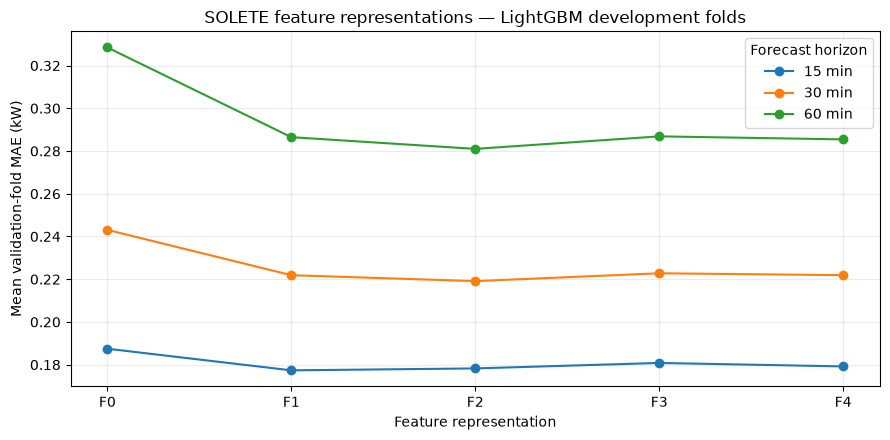

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for horizon in HORIZONS:
    row = accuracy_table.loc[horizon]
    ax.plot(
        ["F0", "F1", "F2", "F3", "F4"],
        [row[name] for name in ("F0", "F1", "F2", "F3", "F4")],
        marker="o", label=f"{horizon} min",
    )
ax.set_xlabel("Feature representation")
ax.set_ylabel("Mean validation-fold MAE (kW)")
ax.set_title("SOLETE feature representations — LightGBM development folds")
ax.legend(title="Forecast horizon")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Preserve the model-development results

We save the fold-level errors, paired validation predictions, and comparison summary. These results support the next notebook's paired uncertainty analysis and detailed interpretation of Panchang effects.

The prediction table records each forecast issue time and valid time, along with actual power, the two persistence baselines, and predictions for all seven representations.

In [8]:
OUTPUT_DIR = PROJECT_ROOT / "results" / "feature_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

metrics_path = OUTPUT_DIR / "solete_development_fold_metrics.csv"
predictions_path = OUTPUT_DIR / "solete_development_predictions.csv.gz"
contrasts_path = OUTPUT_DIR / "solete_development_feature_contrasts.csv"

metrics.to_csv(metrics_path, index=False, float_format="%.12g")
predictions.to_csv(predictions_path, index=False, compression="gzip", float_format="%.12g")
contrasts.to_csv(contrasts_path, index=False, float_format="%.12g")

# Read the saved tables back and verify their structure.
reloaded_metrics = pd.read_csv(metrics_path)
reloaded_predictions = pd.read_csv(predictions_path)
reloaded_contrasts = pd.read_csv(contrasts_path)
assert len(reloaded_metrics) == len(metrics)
assert len(reloaded_predictions) == len(predictions)
assert len(reloaded_contrasts) == len(contrasts)
assert reloaded_predictions[list(FEATURE_NAMES)].notna().all().all()
assert set(reloaded_predictions["horizon_min"]) == set(HORIZONS)

print("Saved model-development results:")
for path in (metrics_path, predictions_path, contrasts_path):
    print(path.relative_to(PROJECT_ROOT), f"({path.stat().st_size / (1024**2):.2f} MB)")
print("NOTEBOOK 06: MODEL DEVELOPMENT CHECKS PASSED")


Saved model-development results:
results/feature_comparison/solete_development_fold_metrics.csv (0.01 MB)
results/feature_comparison/solete_development_predictions.csv.gz (7.13 MB)
results/feature_comparison/solete_development_feature_contrasts.csv (0.00 MB)
NOTEBOOK 06: MODEL DEVELOPMENT CHECKS PASSED


## Interpretation

The development-fold tables show how Gregorian, solar, continuous lunar and Panchang representations affect forecasting error under a common LightGBM configuration. The primary **F3–F4** contrast measures the contribution of categorical Panchang features relative to continuous astronomical features. The sidereal-control contrast examines the same categorical addition when the corresponding continuous sidereal angles are represented explicitly.

The results are from chronological development folds in SOLETE. We will use the saved paired predictions to examine uncertainty, fold consistency and the effects of Panchang representation in the next stage. Conclusions about broader model architectures and datasets require their corresponding comparisons.